### Run Model

In [10]:
import importlib
import solver.airfoil
import solver.vlm

importlib.reload(solver.airfoil)
importlib.reload(solver.vlm)

from solver.vlm import solve_vlm_neuralfoil

import matplotlib.pyplot as plt

Geometry ID: wing_126480edad821890d75a
Coupled CL: 0.683245
Profile CD: 0.007829
Maximum lift mismatch: 7.022e-14
Residual evaluations: 87
VLM time: 0.0518 s
Coupling time: 4.1049 s
Total time: 4.1577 s
y=-1.413 m | chord=0.236 m | alpha=0.865 deg | cl=0.1002 | cd=0.00525 | cm=0.0003
y=-1.409 m | chord=0.237 m | alpha=1.492 deg | cl=0.1722 | cd=0.00537 | cm=0.0005
y=-1.400 m | chord=0.238 m | alpha=2.146 deg | cl=0.2466 | cd=0.00561 | cm=0.0008
y=-1.387 m | chord=0.240 m | alpha=2.774 deg | cl=0.3177 | cd=0.00594 | cm=0.0018
y=-1.370 m | chord=0.243 m | alpha=3.366 deg | cl=0.3834 | cd=0.00627 | cm=0.0031
y=-1.349 m | chord=0.247 m | alpha=3.903 deg | cl=0.4429 | cd=0.00659 | cm=0.0041
y=-1.324 m | chord=0.251 m | alpha=4.377 deg | cl=0.4956 | cd=0.00696 | cm=0.0048
y=-1.295 m | chord=0.256 m | alpha=4.783 deg | cl=0.5417 | cd=0.00732 | cm=0.0050
y=-1.262 m | chord=0.261 m | alpha=5.124 deg | cl=0.5811 | cd=0.00761 | cm=0.0050
y=-1.226 m | chord=0.267 m | alpha=5.407 deg | cl=0.6145 | 

TypeError: unhashable type: 'dict'

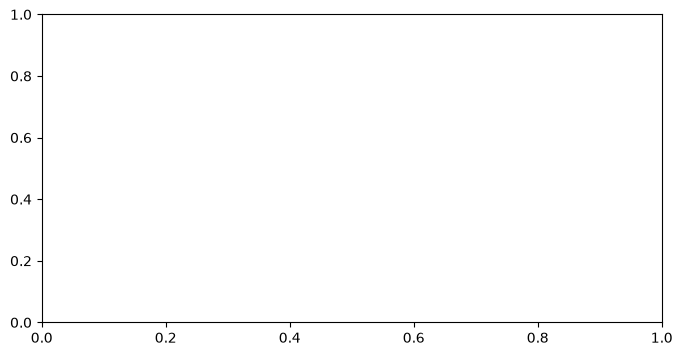

In [14]:
"""Run with: python test_vlm.py (from the project directory)."""

import math
import numpy as np

from solver.geometry import WingParameters, build_wing_geometry
from solver.vlm import solve_vlm_neuralfoil


def test_vlm():
    parameters = WingParameters(
        aspect_ratio=8.0,
        area_m2=1.0,
        taper_ratio=0.5,
        sweep_deg=0.0,
        airfoil="naca0012",
    )
    geometry = build_wing_geometry(parameters)
    result = solve_vlm_neuralfoil(
        geometry,
        velocity=100.0,
        alpha=8.0,
        spanwise_resolution=40,
        chordwise_resolution=4,
        lift_tolerance=1e-6,
    )

    assert math.isfinite(result["CL"]) and result["CL"] > 0
    assert math.isfinite(result["CD_profile"]) and result["CD_profile"] >= 0
    assert result["max_lift_error"] <= 1e-6

    # Both half-wings should cover the full area and have symmetric loading.
    stations = result["stations"]
    np.testing.assert_allclose(
        sum(station["area_m2"] for station in stations), parameters.area_m2,
        rtol=1e-8, atol=1e-10,
    )
    np.testing.assert_allclose(
        [s["y_m"] for s in stations],
        [-s["y_m"] for s in reversed(stations)], atol=1e-10,
    )
    np.testing.assert_allclose(
        [s["cl"] for s in stations],
        [s["cl"] for s in reversed(stations)], rtol=1e-4, atol=1e-6,
    )

    print(f"Geometry ID: {result['geometry_id']}")
    print(f"Coupled CL: {result['CL']:.6f}")
    print(f"Profile CD: {result['CD_profile']:.6f}")
    print(f"Maximum lift mismatch: {result['max_lift_error']:.3e}")
    print(f"Residual evaluations: {result['residual_evaluations']}")
    print(f"VLM time: {result['vlm_runtime_s']:.4f} s")
    print(f"Coupling time: {result['coupling_runtime_s']:.4f} s")
    print(f"Total time: {result['total_runtime_s']:.4f} s")

    for s in stations:
        print(
            f"y={s['y_m']: .3f} m | chord={s['chord_m']:.3f} m | "
            f"alpha={s['alpha_deg']:.3f} deg | cl={s['cl']:.4f} | "
            f"cd={s['cd']:.5f} | cm={s['cm']:.4f}"
        )
    return result


if __name__ == "__main__":
    result = test_vlm()
    plt.figure(figsize=(8, 4))
    plt.plot(result['stations'], [s['cl'] for s in result['stations']], marker="o")
    plt.title("Spanwise Lift Coefficient Distribution")
    plt.xlabel("Spanwise Position")
    plt.ylabel("Lift Coefficient")
    plt.grid(True)
    plt.show()


NameError: name 'stations' is not defined

<Figure size 800x400 with 0 Axes>